In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from src.pickle_functions import load_from_pickle

In [2]:
result_folder = "results"
model_name = "late_fusion"
model_id = 2
with_neutral_class = False
with_n = "_n" if with_neutral_class else ""

In [3]:
def get_pred(task, model_id, result_folder, model_name):
    pred_name = "pred_" + task + "_" + str(model_id)
    root_folder = os.path.join(result_folder, model_name)
    pred_arr = load_from_pickle(pred_name, "predictions", root_folder)
    if task=="classes_pres":
        pred_arr = pred_arr[0]
    return pred_arr

In [4]:
def transform_label_arr(arr):
    new_arr = arr.T.tolist()
    return new_arr

In [5]:
def plot_scatter_plot(true_arr, pred_arr):
    emotions = ['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear']
    for i, emo_i in enumerate(emotions):
        true_emo_i = true_arr[i]
        pred_emo_i = pred_arr[i]
        plt.scatter(true_emo_i, pred_emo_i)
        plt.title(emo_i)
        plt.xlabel("True")
        plt.ylabel("Pred")
        plt.xlim([0, 3])
        plt.ylim([0, 3])
        plt.show()

In [6]:
def plot_scatter_plot_subplots(true_arr, pred_arr):
    emotions = ['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear']
    fig, axs = plt.subplots(2, 3, figsize=(20,12))
    for i, emo_i in enumerate(emotions):
        ax_i = axs[i//3, i%3]
        true_emo_i = true_arr[i]
        pred_emo_i = pred_arr[i]
        ax_i.scatter(true_emo_i, pred_emo_i, alpha=0.25)
        ax_i.set_title(emo_i)
#         ax_i.set_xlim([0, 3])
#         ax_i.set_ylim([0, 3])
        if i//3 == 1:
            ax_i.set_xlabel("True")
        if i%3 == 0:
            ax_i.set_ylabel("Pred")
    plt.show()

In [7]:
def plot_scatter_for_task(task, model_id, result_folder, model_name):
    true_arr = {"raw": true_all,
                "scores_coa": true_coa,
                "classes_pres": true_pres,
                "classes_dom": true_dom}
    pred_arr = get_pred(task, model_id, result_folder, model_name)
    pred_arr = transform_label_arr(pred_arr)
    plot_scatter_plot_subplots(true_arr[task], pred_arr)

In [8]:
def plot_boxplot(true_arr, task_name):
    emotions = ['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear']
    fig, axs = plt.subplots(1, 6, figsize=(20,4))
    for i, tc in enumerate(true_arr):
        ax_i = axs[i]
        ax_i.boxplot(tc)
        ax_i.set_title(emotions[i])
    fig.suptitle(task_name)
    plt.show()

### True labels

In [9]:
true_all_name = "test_true_scores_all" + with_n
true_coa_name = "test_true_scores_coa" + with_n
true_pres_name = "test_true_classes_pres" + with_n
true_dom_name = "test_true_classes_dom" + with_n
true_all = load_from_pickle(true_all_name, "processed_folds", "cmu_mosei")
true_coa = load_from_pickle(true_coa_name, "processed_folds", "cmu_mosei")
true_pres = load_from_pickle(true_pres_name, "processed_folds", "cmu_mosei")
true_dom = load_from_pickle(true_dom_name, "processed_folds", "cmu_mosei")
true_all.shape

(4652, 6)

In [10]:
true_all = transform_label_arr(true_all)
true_coa = transform_label_arr(true_coa)
true_pres = transform_label_arr(true_pres[0])
true_dom = transform_label_arr(true_dom)
len(true_all)

6

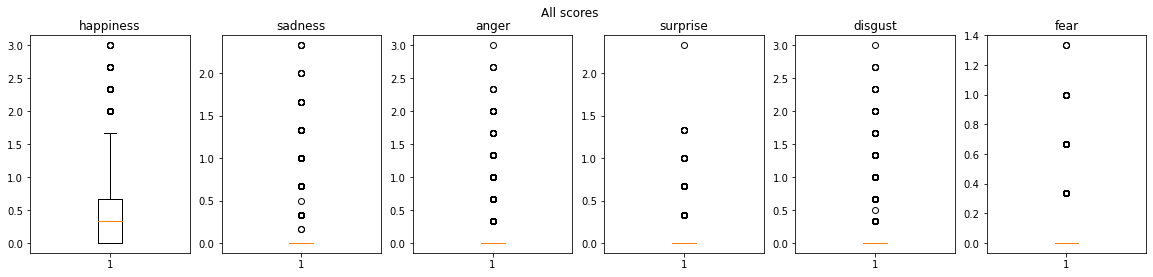

In [11]:
plot_boxplot(true_all, "All scores")

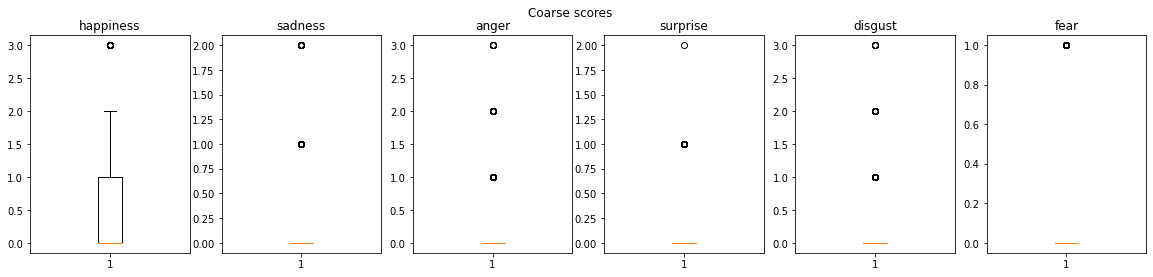

In [12]:
plot_boxplot(true_coa, "Coarse scores")

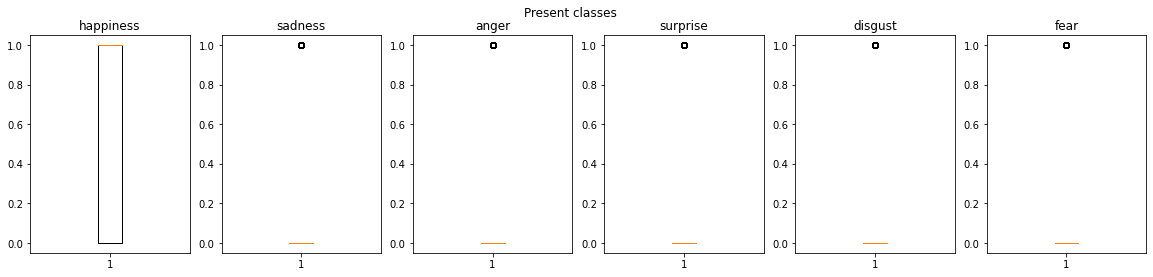

In [13]:
plot_boxplot(true_pres, "Present classes")

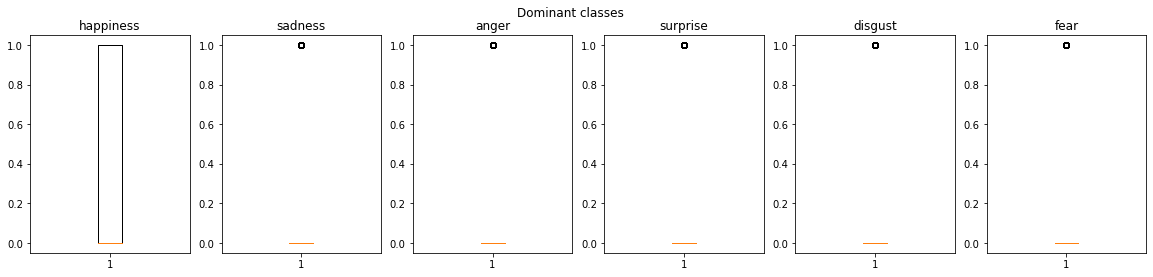

In [14]:
plot_boxplot(true_dom, "Dominant classes")

### Task: all

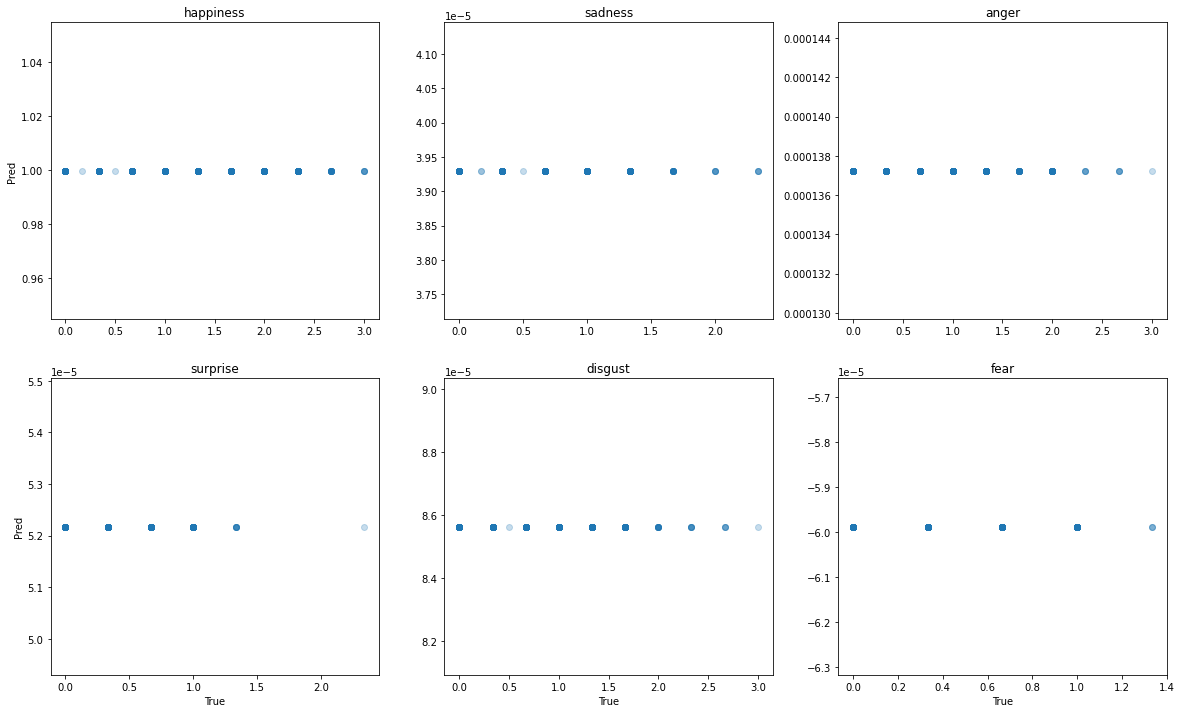

In [15]:
plot_scatter_for_task("raw", model_id, result_folder, model_name)

### Task: coarse

In [16]:
plot_scatter_for_task("scores_coa", model_id, result_folder, model_name)

FileNotFoundError: [Errno 2] No such file or directory: 'results/late_fusion/predictions/pred_scores_coa_2.pkl'

### Task: present

4652
<class 'numpy.ndarray'>


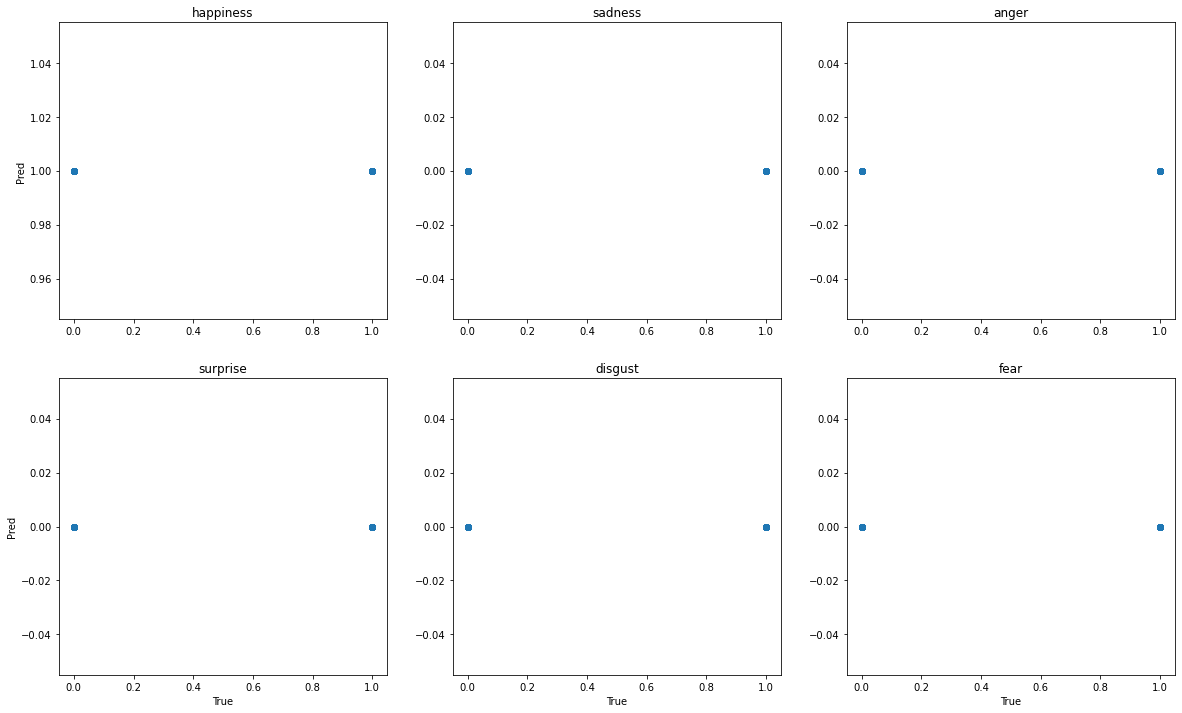

In [63]:
plot_scatter_for_task("classes_pres", model_id, result_folder, model_name)

### Task: dominant

4652
<class 'numpy.ndarray'>


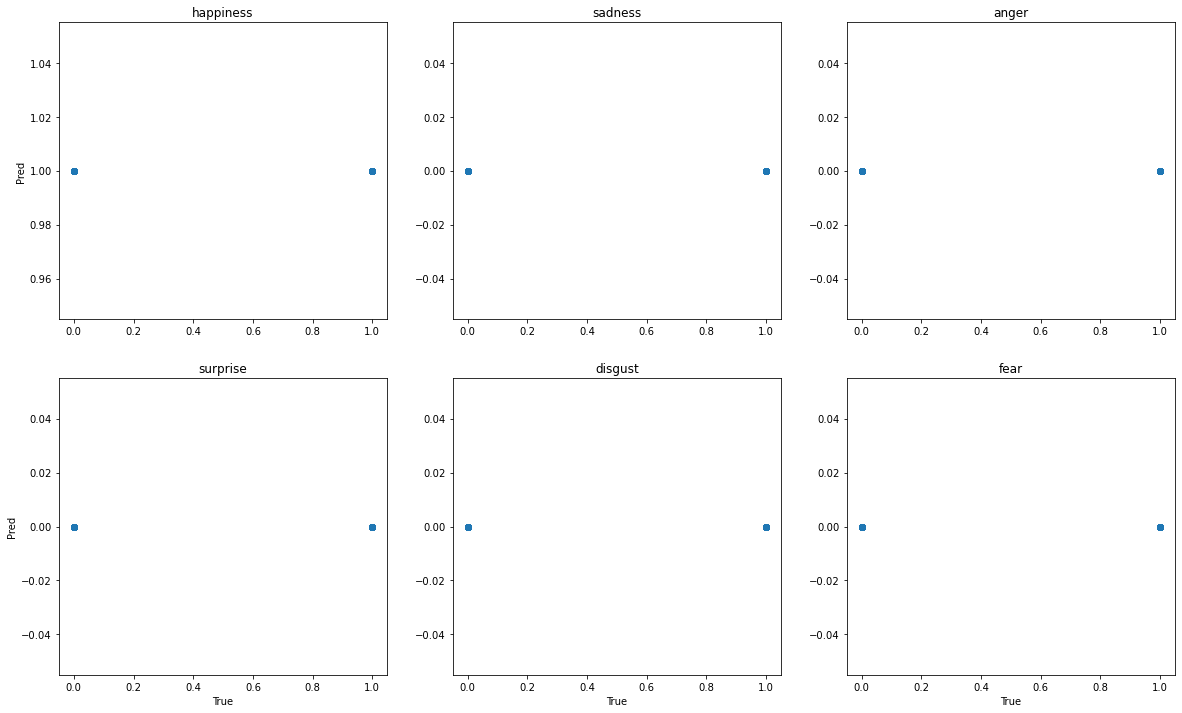

In [64]:
plot_scatter_for_task("classes_dom", model_id, result_folder, model_name)